# Task 3: Predict flow for unseen pumps (Case 2, M4)

**Owner:** Ofri

**Task:** Predict flow using the features available in the case 2 data sets (and any combinations of
these features that you deem relevant). Choose any machine learning model you wish (noted as M4),
and try to get the most accurate prediction possible. Report the test errors of your best-performing
model and argue for your choice of performance metrics. Include a flow versus error plot.
Discuss the hyperparameters of the model, including training and hyperparameter selection details.

- Suggestion 1: Drop the column `elapsed_s` as a feature.
- Suggestion 2: Hold out all data points of a pump together (`GroupKFold`) to avoid data leakage.

**Plan for this notebook**
1. Load the data and clean it.
2. Look at the data, especially how many transient rows exist and whether they behave differently.
3. Choose performance metrics.
4. Set up cross-validation that holds out whole pumps (`GroupKFold`, groups = `pump_id`).
5. Compare M4 against baselines, and check training error against CV error (bias–variance).
6. Feature selection: start from the case 1 features (n, P, Δp), then add each extra feature
   (operating state, current, temperature) and keep it only if the CV error improves clearly.
7. Operating state hypothesis: compare (A) no state info, (B) state as a 0/1 feature,
   (C) two separate models for stable and transient rows.
8. Team plan: StandardScaler → PCA → model, choosing the number of components k with grouped CV.
9. Tune the learning rate λ, the tree size and the number of trees B with validation curves.
10. Fit the final model on all of `train2.csv`, evaluate once on `test2.csv`, plot error versus flow.
11. Ideas for extensions and alternatives.

> **Review changes (added after checking the notebook against the brief and the course slides).**
> Each addition is marked with *Added after review* in the section where it belongs, with the reason.
> In short:
> - **Data cleaning section** (section 2): the brief asks for it explicitly.
> - **Baselines and training vs CV error** (section 7): the brief asks how correctness was assessed, and the
>   slides diagnose high bias vs high variance from training vs validation error (Slides_21 p. 21–22, Slides_3 p. 21).
> - **One-standard-error rule** for feature, state and PCA decisions (Slides_4 p. 26: "if a simple model
>   performs nearly as well as a complicated one, go simple"). Before, the lowest number simply won,
>   even when the differences were far smaller than the spread between pumps.
> - **Proper tuning of λ and B** with validation curves (Slides_15 p. 21–23: "how can we choose the best λ and B?").
>   The old grid had its best value on the edge, and it turned out that sklearn's automatic early stopping
>   (on by default above 10,000 rows) meant the number of trees was never really what the grid said.
> - **PCA loadings and a note that trees do not need scaling** (Slides_10 p. 20–23, Slides_14 p. 15).
> - **Residuals versus predicted flow and a check of the worst pump** (Slides_2 p. 30–33, residual diagnostics).
> - **Speed-up:** CV experiments use every 5th second of the training data (see section 6), so the notebook
>   runs much faster. The final model is still trained on all rows.

In [1]:
import sys
sys.path.append("..")  # so we can import from src/

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from src.data import load_case2, add_features, TARGET

figures_folder = "../report/figures/"
notebook_start_time = time.time()

## 1. Load the data

In [2]:
train_data, test_data = load_case2()
train_data, test_data = add_features(train_data), add_features(test_data)

print("Training data:", train_data.shape)
print("Test data:", test_data.shape)
print("Pumps in training:", sorted(train_data["pump_id"].unique()))
print("Pumps in test:", sorted(test_data["pump_id"].unique()))
print("Pumps in both:", set(train_data["pump_id"]) & set(test_data["pump_id"]))
train_data.head()

Training data: (59950, 15)
Test data: (119900, 15)
Pumps in training: ['99223362_model_01', '99223362_model_02', '99223362_model_03', '99223362_model_04', '99223362_model_05']
Pumps in test: ['99223362_model_06', '99223362_model_07', '99223362_model_08', '99223362_model_09', '99223362_model_10', '99223362_model_11', '99223362_model_12', '99223362_model_13', '99223362_model_14', '99223362_model_15']
Pumps in both: set()


,pump_id,elapsed_s,operating_state,speed_rpm,power_w,inlet_pressure_bar,outlet_pressure_bar,measured_head_m,current_a,torque_nm,temperature_c,flow_m3_h,speed_krpm,power_kw,pressure_difference_bar
0,99223362_model_01,0.0,stable,3221.860983,355.670823,2.412831,3.164026,7.671249,0.568770,1.029636,27.618585,5.71711,3.221861,0.355671,0.751195
1,99223362_model_01,1.0,stable,3198.279924,346.603569,2.423269,3.174624,7.672882,0.594010,1.057619,27.656450,5.71711,3.198280,0.346604,0.751355
2,99223362_model_01,2.0,stable,3197.314725,355.093283,2.302593,3.190288,9.065196,0.572038,1.028020,27.124331,5.71711,3.197315,0.355093,0.887695
3,99223362_model_01,3.0,stable,3187.103203,346.438509,2.345914,3.102848,7.729854,0.599680,1.047076,27.939147,5.71711,3.187103,0.346439,0.756934
4,99223362_model_01,4.0,stable,3212.059205,358.906087,2.343708,3.098729,7.710320,0.590551,1.063113,27.277784,5.71711,3.212059,0.358906,0.755021


In [3]:
# add_features (src/data.py) already added speed_krpm, power_kw and pressure_difference_bar, as in Task 1.
# Here we also add a 0/1 version of the operating state.
for dataset in [train_data, test_data]:
    dataset["is_transient"] = (dataset["operating_state"] == "transient").astype(int)

target_name = TARGET
y_train = train_data[target_name]
y_test = test_data[target_name]

train_data.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
elapsed_s,59950.0,5994.500,3461.244,0.000,2997.000,5994.500,8992.000,11989.000
speed_rpm,59950.0,2502.029,824.423,988.945,1807.310,2500.068,3196.285,4076.533
power_w,59950.0,307.221,249.526,21.441,105.219,230.926,447.625,1176.804
inlet_pressure_bar,59950.0,1.753,0.397,0.916,1.430,1.761,2.074,2.566
outlet_pressure_bar,59950.0,2.189,0.494,0.994,1.836,2.183,2.535,3.735
measured_head_m,59950.0,4.455,3.054,-1.959,1.962,3.786,6.489,14.231
current_a,59950.0,0.504,0.409,0.036,0.173,0.379,0.735,1.907
torque_nm,59950.0,1.007,0.560,0.205,0.546,0.879,1.360,2.761
temperature_c,59950.0,26.759,1.184,22.405,26.211,27.013,27.579,29.746
flow_m3_h,59950.0,12.667,8.442,0.067,6.060,11.133,17.941,42.203


## 2. Data cleaning

> *Added after review:* the brief asks the report to "argue which features needed cleaning and explain why".
> The checks below go through each possible problem and record the decision.

In [4]:
print("Missing values (train, test):", train_data.isna().sum().sum(), test_data.isna().sum().sum())
print("Duplicate rows (train, test):", train_data.duplicated().sum(), test_data.duplicated().sum())

# 1. Negative pressure rise / head
for name, dataset in [("train", train_data), ("test", test_data)]:
    negative = dataset["pressure_difference_bar"] < 0
    print(f"\n{name}: rows with negative Δp: {negative.sum()} ({100 * negative.mean():.1f} %), "
          f"negative head: {(dataset['measured_head_m'] < 0).sum()}")
    print(f"  median speed in those rows: {dataset.loc[negative, 'speed_rpm'].median():.0f} rpm "
          f"(all rows: {dataset['speed_rpm'].median():.0f} rpm)")
    print(f"  median flow in those rows: {dataset.loc[negative, target_name].median():.1f} m³/h")

# 2. Is measured head just Δp in other units? H = Δp / (ρ g), with Δp in Pa, ρ = 1000 kg/m³, g = 9.81 m/s²
head_from_pressure = train_data["pressure_difference_bar"] * 1e5 / (1000 * 9.81)
clear_rows = train_data["pressure_difference_bar"].abs() > 0.1
print("\nmeasured head / head computed from Δp (median):",
      round((train_data.loc[clear_rows, "measured_head_m"] / head_from_pressure[clear_rows]).median(), 4))
print("correlation between measured head and Δp:",
      round(np.corrcoef(train_data["measured_head_m"], train_data["pressure_difference_bar"])[0, 1], 5))

# 3. Very small flows (matter for relative errors)
print("\nRows with flow below 0.5 m³/h (train):", (y_train < 0.5).sum(), "of", len(y_train))

# 4. Temperature per pump
print("\nMean temperature per pump, train:", train_data.groupby("pump_id")["temperature_c"].mean().round(2).tolist())
print("Mean temperature per pump, test: ", test_data.groupby("pump_id")["temperature_c"].mean().round(2).tolist())

Missing values (train, test): 0 0


Duplicate rows (train, test): 0 0

train: rows with negative Δp: 522 (0.9 %), negative head: 522
  median speed in those rows: 1200 rpm (all rows: 2500 rpm)
  median flow in those rows: 10.8 m³/h

test: rows with negative Δp: 1085 (0.9 %), negative head: 1085
  median speed in those rows: 1190 rpm (all rows: 2505 rpm)
  median flow in those rows: 10.5 m³/h

measured head / head computed from Δp (median): 1.0018
correlation between measured head and Δp: 1.0

Rows with flow below 0.5 m³/h (train): 893 of 59950

Mean temperature per pump, train: [27.45, 24.82, 27.47, 26.82, 27.23]
Mean temperature per pump, test:  [25.05, 26.84, 25.55, 25.26, 24.72, 26.77, 26.89, 27.59, 25.84, 27.34]


**Decisions**
- **No missing values or duplicates**, so nothing to impute or remove.
- **Negative Δp and head (about 1 % of rows):** these are kept. They happen at low speed, where the pump
  builds almost no pressure, so small negative values are measurement noise around zero rather than broken
  rows. They appear in both train and test at the same rate, and head and Δp agree on them, so they are
  real operating points the model must handle. Removing them from the test set would make the test error look
  better than it really is.
- **Measured head is exactly Δp in other units** (ratio 1.00, correlation 1.0). It is dropped as a feature,
  because it adds no new information.
- **Flows close to 0** are kept. They are real, but they make percentage errors explode, which affects the
  choice of metrics (section 5).
- **Temperature is mostly a per-pump constant** (one training pump runs at about 24.8 °C, the others at 27–27.5 °C).
  A model can use it to recognise *which pump* it is looking at instead of learning physics, which does not
  transfer to new pumps. This is tested in section 8.
- `elapsed_s` and `pump_id` are not used as features (assignment suggestion 1; test pumps are new).

## 3. Exploratory look at the operating state

First step of the hypothesis: count the transient rows per pump. If there are only a few, a separate
transient model would have too little data to learn from.

In [5]:
print("Training set: rows per pump and operating state")
print(pd.crosstab(train_data["pump_id"], train_data["operating_state"]))
print("\nTest set: rows per pump and operating state")
print(pd.crosstab(test_data["pump_id"], test_data["operating_state"]))

Training set: rows per pump and operating state
operating_state    stable  transient
pump_id                             
99223362_model_01    6000       5990
99223362_model_02    6000       5990
99223362_model_03    6000       5990
99223362_model_04    6000       5990
99223362_model_05    6000       5990

Test set: rows per pump and operating state
operating_state    stable  transient
pump_id                             
99223362_model_06    6000       5990
99223362_model_07    6000       5990
99223362_model_08    6000       5990
99223362_model_09    6000       5990
99223362_model_10    6000       5990
99223362_model_11    6000       5990
99223362_model_12    6000       5990
99223362_model_13    6000       5990
99223362_model_14    6000       5990
99223362_model_15    6000       5990


In [6]:
# How are the states ordered in time? (look at the first 60 seconds of one pump)
one_pump = train_data[train_data["pump_id"] == train_data["pump_id"].iloc[0]].head(60)
print(one_pump[["elapsed_s", "operating_state", "speed_rpm", "flow_m3_h"]].iloc[::5].to_string(index=False))

 elapsed_s operating_state   speed_rpm  flow_m3_h
       0.0          stable 3221.860983   5.717110
       5.0          stable 3207.459656   5.717110
      10.0       transient 3076.277045   5.717110
      15.0       transient 2351.884015  10.753535
      20.0          stable 1786.844542  15.789960
      25.0          stable 1788.780885  15.789960
      30.0       transient 1750.327711  15.789960
      35.0       transient 1634.931773  10.345459
      40.0          stable 1525.542748   4.900958
      45.0          stable 1521.981419   4.900958
      50.0       transient 1580.846768   4.900958
      55.0       transient 1900.998706   4.651360


**Observation:** each pump has about half stable and half transient rows (6000 vs 5990), and the
states alternate in blocks of 10 seconds. There are plenty of transient rows (about 30,000 in training,
from all 5 pumps), so training a separate transient model is possible.

The flow label is **constant within each 10-second stable block**, while speed, power and pressure vary
slightly from second to second (sensor noise). During transient blocks the flow moves from one level to the
next. Rows one second apart are therefore almost identical, which is why a normal shuffled `KFold` would leak:
the model would be validated on near-copies of rows it trained on.

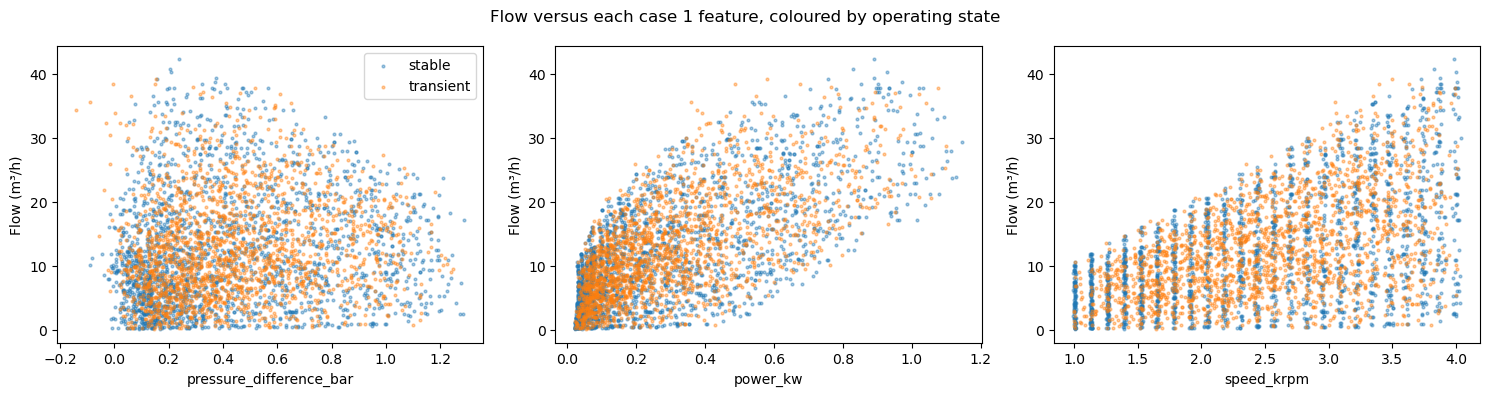

                flow_m3_h        speed_krpm        power_kw         \
                     mean    std       mean    std     mean    std   
operating_state                                                      
stable             12.667  9.048      2.502  0.902    0.317  0.273   
transient          12.666  7.788      2.502  0.739    0.298  0.223   

                pressure_difference_bar         
                                   mean    std  
operating_state                                 
stable                            0.437  0.324  
transient                         0.435  0.271  


In [7]:
# Does the flow relate to the inputs differently in the two states?
plot_sample = train_data.sample(4000, random_state=0)
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, feature in zip(axes, ["pressure_difference_bar", "power_kw", "speed_krpm"]):
    for state, color in [("stable", "tab:blue"), ("transient", "tab:orange")]:
        rows = plot_sample[plot_sample["operating_state"] == state]
        axis.scatter(rows[feature], rows[target_name], s=4, alpha=0.4, color=color, label=state)
    axis.set_xlabel(feature)
    axis.set_ylabel("Flow (m³/h)")
axes[0].legend()
plt.suptitle("Flow versus each case 1 feature, coloured by operating state")
plt.tight_layout()
plt.savefig(figures_folder + "task3_flow_vs_features_by_state.png", dpi=200, bbox_inches="tight")
plt.show()

print(train_data.groupby("operating_state")[
    ["flow_m3_h", "speed_krpm", "power_kw", "pressure_difference_bar"]].agg(["mean", "std"]).round(3))

## 4. Correlation between candidate features

This shows which features carry almost the same information (redundancy):
- power, torque and speed are linked by P = τ·ω
- measured head is Δp divided by a constant (ρg), see section 2
- current follows power closely

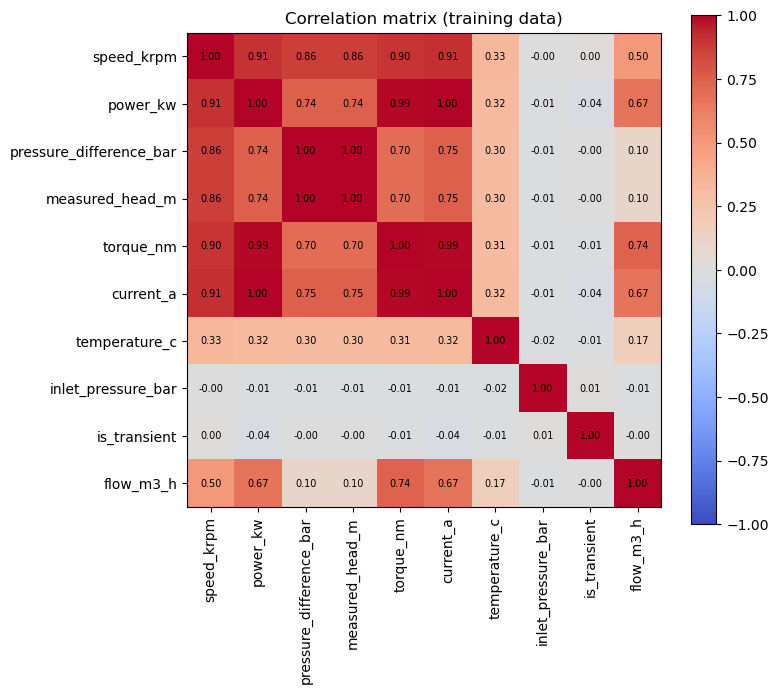

In [8]:
candidate_columns = ["speed_krpm", "power_kw", "pressure_difference_bar", "measured_head_m",
                     "torque_nm", "current_a", "temperature_c", "inlet_pressure_bar",
                     "is_transient", target_name]
correlation_matrix = train_data[candidate_columns].corr()

figure, axis = plt.subplots(figsize=(8, 7))
image = axis.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
axis.set_xticks(range(len(candidate_columns)), candidate_columns, rotation=90)
axis.set_yticks(range(len(candidate_columns)), candidate_columns)
for i in range(len(candidate_columns)):
    for j in range(len(candidate_columns)):
        axis.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(image)
plt.title("Correlation matrix (training data)")
plt.tight_layout()
plt.savefig(figures_folder + "task3_correlation_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

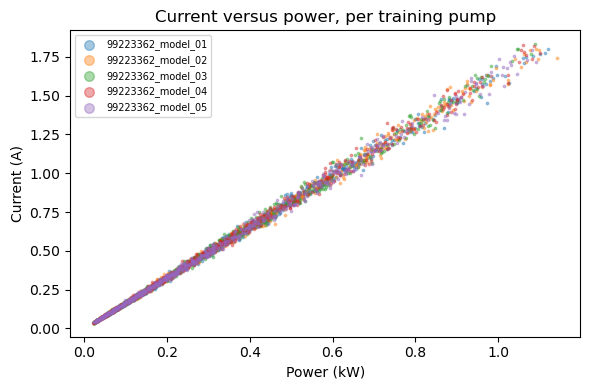

Ratio current / power per pump (mean):
pump_id
99223362_model_01    1.641
99223362_model_02    1.641
99223362_model_03    1.641
99223362_model_04    1.641
99223362_model_05    1.641
dtype: float64


In [9]:
# Current: does the current-to-power relationship look the same for every pump?
# If it differs between pumps (different motors), a model relying on current may not transfer to new pumps.
figure, axis = plt.subplots(figsize=(6, 4))
for pump_id, rows in train_data.groupby("pump_id"):
    rows = rows.sample(800, random_state=0)
    axis.scatter(rows["power_kw"], rows["current_a"], s=3, alpha=0.4, label=pump_id)
axis.set_xlabel("Power (kW)")
axis.set_ylabel("Current (A)")
axis.legend(markerscale=4, fontsize=7)
plt.title("Current versus power, per training pump")
plt.tight_layout()
plt.show()

print("Ratio current / power per pump (mean):")
print((train_data["current_a"] / train_data["power_kw"]).groupby(train_data["pump_id"]).mean().round(3))

## 5. Performance metrics

| Metric | Why it is included |
|---|---|
| **RMSE** (m³/h) | Main metric for all CV decisions, same as Task 1. Same units as the flow, and it punishes large errors strongly (squared-error loss), which matters because a big misreading of the flow is worse than several small ones. |
| **MAE** (m³/h) | Easy to explain: "on average the prediction is off by X m³/h" (absolute-error loss). Less sensitive to a few large errors, so comparing it to RMSE tells us whether errors are spread evenly or dominated by a few big misses. |
| **R²** | Unit-free share of the variation in flow explained. Useful for comparing with case 1. |
| **Relative error for Q ≥ 1 m³/h** (%) | A 1 m³/h error is large at Q = 2 but small at Q = 40. The usual MAPE explodes because there are rows with flow close to 0 (section 2), so we only compute it where Q ≥ 1. |

We also report the errors **per pump** and **per operating state**, to see whether the model fails on
specific pumps or during transients.

In [10]:
def rmse(y_true, y_predicted):
    return np.sqrt(mean_squared_error(y_true, y_predicted))


def compute_errors(y_true, y_predicted):
    y_true = np.asarray(y_true)
    y_predicted = np.asarray(y_predicted)
    not_tiny_flow = y_true >= 1
    return {
        "RMSE": rmse(y_true, y_predicted),
        "MAE": mean_absolute_error(y_true, y_predicted),
        "R2": r2_score(y_true, y_predicted),
        "relative_error_pct": 100 * np.mean(
            np.abs(y_true[not_tiny_flow] - y_predicted[not_tiny_flow]) / y_true[not_tiny_flow]),
    }

## 6. Cross-validation that holds out whole pumps

There are 5 training pumps, so `GroupKFold(n_splits=5)` holds out exactly one pump per fold
(leave-one-pump-out). Each CV score therefore measures how well the model predicts a pump it has
never seen, which is exactly the situation of the test set.

> *Added after review (speed-up):* all CV experiments use **every 5th second** of the training data
> (seconds 2, 7, 12, … of each recording, so each 10-second block contributes one row from its start and one
> from its middle). Rows one second apart are near-copies (section 3), so this keeps almost all the
> information while making every model 5× cheaper to train. The cell below checks that the CV error is
> about the same as on all rows. The final model in section 12 is trained on **all** rows.

The function below returns the **out-of-fold predictions**: every row gets a prediction from a model that
did not see its pump. This lets us compute any metric afterwards, and also lets us score the "two separate
models" version on exactly the same rows as the others. It also returns the **training error**, needed for
the bias–variance check in section 7.

In [11]:
cv_data = train_data[train_data["elapsed_s"] % 5 == 2].reset_index(drop=True)
y_cv = cv_data[target_name]
number_of_folds = 5
cv_splits = list(GroupKFold(n_splits=number_of_folds).split(cv_data, y_cv, groups=cv_data["pump_id"]))
print("Rows used for CV:", len(cv_data), "of", len(train_data))

for fold_number, (train_rows, validation_rows) in enumerate(cv_splits):
    print(f"Fold {fold_number}: validation pump = {cv_data['pump_id'].iloc[validation_rows].unique()}")


def out_of_fold_predictions(make_model, feature_names, split_by_state=False, shuffle_target=False):
    # split_by_state=True trains one model on stable rows and another on transient rows,
    # and predicts each validation row with the model for its own state.
    # shuffle_target=True trains on randomly shuffled flow values (a "no real pattern" baseline).
    predictions = np.zeros(len(cv_data))
    training_rmse_per_fold = []
    random_generator = np.random.default_rng(42)
    for train_rows, validation_rows in cv_splits:
        fold_train = cv_data.iloc[train_rows]
        fold_validation = cv_data.iloc[validation_rows]
        fold_train_predictions = np.zeros(len(fold_train))
        for state in (["stable", "transient"] if split_by_state else ["all"]):
            train_mask = np.ones(len(fold_train), dtype=bool) if state == "all" else \
                (fold_train["operating_state"] == state).to_numpy()
            validation_mask = np.ones(len(fold_validation), dtype=bool) if state == "all" else \
                (fold_validation["operating_state"] == state).to_numpy()
            target = fold_train.loc[train_mask, target_name].to_numpy()
            if shuffle_target:
                target = random_generator.permutation(target)
            model = make_model()
            model.fit(fold_train.loc[train_mask, feature_names], target)
            fold_train_predictions[train_mask] = model.predict(fold_train.loc[train_mask, feature_names])
            predictions[validation_rows[validation_mask]] = model.predict(
                fold_validation.loc[validation_mask, feature_names])
        training_rmse_per_fold.append(rmse(fold_train[target_name], fold_train_predictions))
    return predictions, np.mean(training_rmse_per_fold)


def cv_summary(result):
    # Overall CV errors, the standard error of the CV RMSE over the 5 held-out pumps, and the training RMSE
    predictions, training_rmse = result
    summary = compute_errors(y_cv, predictions)
    rmse_per_pump = [rmse(y_cv.iloc[rows], predictions[rows]) for _, rows in cv_splits]
    summary["RMSE_SE"] = np.std(rmse_per_pump, ddof=1) / np.sqrt(number_of_folds)
    summary["train_RMSE"] = training_rmse
    return summary


def one_standard_error_choice(results_table, candidates_simplest_first):
    # Slides_4 p. 26: pick the simplest candidate whose CV RMSE is within one standard error of the best.
    best_name = results_table.loc[candidates_simplest_first, "RMSE"].idxmin()
    threshold = results_table.loc[best_name, "RMSE"] + results_table.loc[best_name, "RMSE_SE"]
    for name in candidates_simplest_first:
        if results_table.loc[name, "RMSE"] <= threshold:
            return name, best_name, threshold

Rows used for CV: 11990 of 59950
Fold 0: validation pump = ['99223362_model_05']
Fold 1: validation pump = ['99223362_model_04']
Fold 2: validation pump = ['99223362_model_03']
Fold 3: validation pump = ['99223362_model_02']
Fold 4: validation pump = ['99223362_model_01']


## 7. Choosing the model (M4), baselines and a bias–variance check

Candidates:
- **Baseline: predict the mean flow.** Any useful model must beat this.
- **Baseline: M4 trained on shuffled flow values.** If this scored well, the model would be finding
  patterns that are not really there (Slides_9 p. 25–26).
- **Baseline: polynomial linear regression (degree 3)**, the best model from Task 1.
- **M4: Gradient boosting** (`HistGradientBoostingRegressor`). Boosting fits many small regression trees one
  after the other: each new tree is fitted to the residuals (the errors) of the trees so far, and its
  prediction is added with a small weight λ, the learning rate (Slides_15 p. 18–21). Each tree on its own is a
  weak learner with high bias; adding them step by step reduces the bias. Reasons for choosing it:
  - The relationship between flow and the inputs is nonlinear (we saw this in Tasks 0–2), and boosting
    finds nonlinear effects and interactions by itself, without us choosing polynomial terms.
  - It is fast on large data sets (it bins the features into histograms), so grouped CV and tuning are cheap.
  - Trees do not need feature scaling, and redundant features do not make it unstable like they do in
    linear regression.

For sections 7–10 every boosting model uses the same fixed settings (λ = 0.1, 100 trees, 31 leaves per tree,
early stopping switched **off**), so that comparisons only differ in the thing being compared.
The settings are tuned in section 11.

> *Added after review:* the two "dumb" baselines and the `train_RMSE` column. The brief asks how we checked
> that the implementation does what it should. The baselines show the pipeline learns real structure, and
> comparing training error with CV error is the course's way to diagnose high bias vs high variance
> (Slides_21 p. 21–22): a training error much lower than the validation error means high variance (overfitting).

In [12]:
case1_features = ["speed_krpm", "power_kw", "pressure_difference_bar"]


def make_linear_baseline():
    return make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(),
                         LinearRegression())


def make_boosting(pca_components=None, **hyperparameters):
    # Returns a function that builds a fresh, untrained model (a new one is needed for every CV fold).
    # early_stopping=False: otherwise sklearn silently turns early stopping on above 10,000 rows and
    # stops after an unknown number of trees, using a random (not pump-based) validation split.
    # With pca_components set, the inputs are first scaled and reduced with PCA (section 10).
    # Scaler and PCA sit inside the pipeline, so in CV they are fitted on the training pumps only.
    settings = dict(learning_rate=0.1, max_iter=100, max_leaf_nodes=31,
                    min_samples_leaf=20, early_stopping=False, random_state=42)
    settings.update(hyperparameters)

    def make_model():
        booster = HistGradientBoostingRegressor(**settings)
        if pca_components is None:
            return booster
        return make_pipeline(StandardScaler(), PCA(n_components=pca_components), booster)
    return make_model


model_comparison = {
    "Predict the mean": cv_summary(out_of_fold_predictions(lambda: DummyRegressor(strategy="mean"),
                                                           case1_features)),
    "M4 on shuffled flow": cv_summary(out_of_fold_predictions(make_boosting(), case1_features,
                                                              shuffle_target=True)),
    "Linear regression, degree 3": cv_summary(out_of_fold_predictions(make_linear_baseline, case1_features)),
    "Gradient boosting (M4)": cv_summary(out_of_fold_predictions(make_boosting(), case1_features)),
}
pd.DataFrame(model_comparison).T.round(3)

C:\Users\Ofri\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Ofri\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Ofri\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Ofri\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

,RMSE,MAE,R2,relative_error_pct,RMSE_SE,train_RMSE
Predict the mean,8.375,6.821,-0.004,100.931,0.215,8.357
M4 on shuffled flow,8.528,6.918,-0.041,102.140,0.186,8.528
"Linear regression, degree 3",1.979,1.523,0.944,16.214,0.118,1.774
Gradient boosting (M4),1.831,1.398,0.952,13.444,0.110,1.454


In [13]:
# Check of the speed-up: the same M4 setup, CV on all training rows instead of every 5th second.
full_splits = GroupKFold(n_splits=number_of_folds).split(train_data, y_train, groups=train_data["pump_id"])
full_predictions = np.zeros(len(train_data))
for train_rows, validation_rows in full_splits:
    model = make_boosting()()
    model.fit(train_data.iloc[train_rows][case1_features], y_train.iloc[train_rows])
    full_predictions[validation_rows] = model.predict(train_data.iloc[validation_rows][case1_features])
print(f"CV RMSE, every 5th second: {model_comparison['Gradient boosting (M4)']['RMSE']:.3f}")
print(f"CV RMSE, all rows:         {rmse(y_train, full_predictions):.3f}")

CV RMSE, every 5th second: 1.831
CV RMSE, all rows:         1.783


**Reading the table**
- Predicting the mean and the shuffled-flow model are both far worse than the real models, so M4 is learning
  real structure, not noise.
- Gradient boosting beats the linear baseline.
- `RMSE_SE` is the standard error of the CV RMSE over the 5 held-out pumps. Differences smaller than this
  are not meaningful.
- Training error vs CV error: if `train_RMSE` is much lower than `RMSE`, the model fits the training pumps
  better than it predicts new ones (variance). Part of that gap is unavoidable here, because the held-out pump
  really is different from the training pumps.

## 8. Feature selection with grouped CV

Start from the case 1 features (n, P, Δp). Then add each extra feature **one at a time** (forward selection,
Slides_2 p. 29, Slides_4 p. 14–17) and see whether the CV RMSE on held-out pumps improves.

Features that were left out on purpose (logic, see sections 2 and 4):
- `elapsed_s`: a clock, not a property of the pump (assignment suggestion 1)
- `pump_id`: the test pumps are all new, so the ID carries no usable information
- `measured_head_m`: exactly Δp in other units (section 2)
- `torque_nm`: duplicates power and speed (P = τ·ω)

> *Added after review:* the decision now uses the **one-standard-error rule** (Slides_4 p. 26): keep the
> simplest feature set whose CV RMSE is within one standard error of the best one. Before, any feature that
> lowered the CV RMSE at all was kept, even if the improvement was much smaller than the uncertainty
> from having only 5 pumps. The slides also warn against testing too many options ("multiple testing").

In [14]:
extra_features = ["is_transient", "current_a", "temperature_c"]

feature_sets = {"case 1 features": case1_features}
for extra in extra_features:
    feature_sets["+ " + extra] = case1_features + [extra]

feature_results = {name: cv_summary(out_of_fold_predictions(make_boosting(), features))
                   for name, features in feature_sets.items()}
feature_results_table = pd.DataFrame(feature_results).T

# Combination of every extra feature that lowered the CV RMSE on its own
baseline_rmse = feature_results_table.loc["case 1 features", "RMSE"]
helpful_features = [extra for extra in extra_features
                    if feature_results_table.loc["+ " + extra, "RMSE"] < baseline_rmse]
if len(helpful_features) > 1:
    feature_sets["combined"] = case1_features + helpful_features
    feature_results_table.loc["combined"] = pd.Series(cv_summary(
        out_of_fold_predictions(make_boosting(), feature_sets["combined"])))
feature_results_table.round(3)

,RMSE,MAE,R2,relative_error_pct,RMSE_SE,train_RMSE
case 1 features,1.831,1.398,0.952,13.444,0.110,1.454
+ is_transient,1.827,1.397,0.952,13.442,0.110,1.452
+ current_a,1.801,1.369,0.954,12.843,0.113,1.400
+ temperature_c,1.976,1.520,0.944,14.415,0.108,1.428
combined,1.804,1.370,0.953,12.855,0.112,1.399


In [15]:
single_additions = feature_results_table.loc[["+ " + extra for extra in extra_features], "RMSE"].sort_values()
candidates_simplest_first = ["case 1 features"] + list(single_additions.index) + \
    (["combined"] if "combined" in feature_results_table.index else [])
chosen_name, best_name, threshold = one_standard_error_choice(feature_results_table, candidates_simplest_first)

print(f"Lowest CV RMSE: {best_name} ({feature_results_table.loc[best_name, 'RMSE']:.3f}), "
      f"one-SE threshold = {threshold:.3f}")
print("Chosen by the one-standard-error rule:", chosen_name)
selected_features = feature_sets[chosen_name]
print("Selected features:", selected_features)

Lowest CV RMSE: + current_a (1.801), one-SE threshold = 1.915
Chosen by the one-standard-error rule: case 1 features
Selected features: ['speed_krpm', 'power_kw', 'pressure_difference_bar']


**Temperature** makes the error clearly worse. Section 2 explains why: temperature is almost constant per pump,
so the model uses it to tell the training pumps apart, and that does not carry over to new pumps.

## 9. Operating state hypothesis: one model or two?

Three versions, all scored on the **same** held-out rows with the same folds:
- **A:** one model, no state information
- **B:** one model, with `is_transient` as a 0/1 feature
- **C:** two separate models (stable and transient), each validation row predicted by the model for its state

For each version we report the overall error and the error on stable and on transient rows separately.

> *Added after review:* the choice now uses the one-standard-error rule with A as the simplest option, instead
> of an arbitrary "C must be 2 % better" threshold.

In [16]:
features_without_state = [name for name in selected_features if name != "is_transient"]
features_with_state = features_without_state + ["is_transient"]

state_versions = {
    "A: one model, no state": out_of_fold_predictions(make_boosting(), features_without_state),
    "B: one model, state as feature": out_of_fold_predictions(make_boosting(), features_with_state),
    "C: two separate models": out_of_fold_predictions(make_boosting(), features_without_state,
                                                      split_by_state=True),
}

stable_rows = (cv_data["operating_state"] == "stable").to_numpy()
state_results = {}
for version_name, result in state_versions.items():
    predictions = result[0]
    state_results[version_name] = {
        **cv_summary(result),
        "RMSE stable": rmse(y_cv[stable_rows], predictions[stable_rows]),
        "RMSE transient": rmse(y_cv[~stable_rows], predictions[~stable_rows]),
    }
state_results_table = pd.DataFrame(state_results).T
state_results_table[["RMSE", "RMSE_SE", "train_RMSE", "RMSE stable", "RMSE transient", "MAE"]].round(3)

,RMSE,RMSE_SE,train_RMSE,RMSE stable,RMSE transient,MAE
"A: one model, no state",1.831,0.110,1.454,1.842,1.820,1.398
"B: one model, state as feature",1.827,0.110,1.452,1.835,1.819,1.397
C: two separate models,1.877,0.107,1.383,1.906,1.847,1.427


In [17]:
chosen_version, best_version, threshold = one_standard_error_choice(state_results_table, list(state_versions))
print(f"Lowest CV RMSE: {best_version}, one-SE threshold = {threshold:.3f}")
print("Chosen by the one-standard-error rule:", chosen_version)

use_separate_models = chosen_version.startswith("C")
final_features = features_with_state if chosen_version.startswith("B") else features_without_state
print("Use two separate models:", use_separate_models)
print("Final features:", final_features)

Lowest CV RMSE: B: one model, state as feature, one-SE threshold = 1.937
Chosen by the one-standard-error rule: A: one model, no state
Use two separate models: False
Final features: ['speed_krpm', 'power_kw', 'pressure_difference_bar']


## 10. PCA: StandardScaler → PCA → model (team plan)

Instead of choosing features by hand, give the model **all** sensor features and let PCA compress them
into k components. PCA finds the directions in which the (scaled) features vary the most, so groups of
redundant features (power/torque/current) are merged into one component each.

- The scaler is needed because PCA is driven by variance: without scaling, the feature with the
  largest numbers would dominate (Slides_10 p. 25–27).
- Scaler and PCA are inside the pipeline, so in each fold they are fitted on the training pumps only.
- k is a tuning parameter chosen with the same leave-one-pump-out CV (Slides_10 p. 20).
- `is_transient` is left out of PCA, because it is a 0/1 label rather than a measurement.

> *Added after review:* the scaler only matters for PCA. Trees, and therefore gradient boosting, are invariant
> to the scaling of features (Slides_14 p. 15), so the models without PCA use the raw features.
> The PCA loadings are now printed, because the slides say to "think hard about what the principal
> components really measure" (Slides_10 p. 23), and they explain why PCA does worse here.

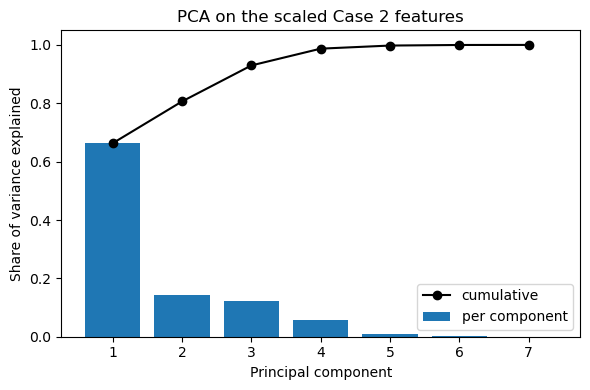

Cumulative explained variance: [0.663 0.806 0.93  0.987 0.998 1.    1.   ]

Loadings (how much each feature contributes to each component):
                          PC1   PC2   PC3   PC4
speed_krpm               0.45  0.02 -0.06  0.22
power_kw                 0.45  0.02 -0.10 -0.27
pressure_difference_bar  0.39  0.00 -0.03  0.82
inlet_pressure_bar      -0.01  0.99  0.13  0.00
torque_nm                0.45  0.02 -0.11 -0.36
current_a                0.45  0.02 -0.10 -0.27
temperature_c            0.19 -0.13  0.97 -0.06


In [18]:
pca_features = ["speed_krpm", "power_kw", "pressure_difference_bar", "inlet_pressure_bar",
                "torque_nm", "current_a", "temperature_c"]

# Explained variance and loadings on the scaled training data (for interpretation, not used for any decision)
fitted_pca = PCA().fit(StandardScaler().fit_transform(train_data[pca_features]))
explained_variance = fitted_pca.explained_variance_ratio_

figure, axis = plt.subplots(figsize=(6, 4))
component_numbers = np.arange(1, len(pca_features) + 1)
axis.bar(component_numbers, explained_variance, label="per component")
axis.plot(component_numbers, np.cumsum(explained_variance), "o-", color="black", label="cumulative")
axis.set_xlabel("Principal component")
axis.set_ylabel("Share of variance explained")
axis.set_title("PCA on the scaled Case 2 features")
axis.legend()
plt.tight_layout()
plt.savefig(figures_folder + "task3_pca_explained_variance.png", dpi=200, bbox_inches="tight")
plt.show()
print("Cumulative explained variance:", np.round(np.cumsum(explained_variance), 3))

loadings = pd.DataFrame(fitted_pca.components_.T, index=pca_features,
                        columns=[f"PC{number}" for number in component_numbers])
print("\nLoadings (how much each feature contributes to each component):")
print(loadings.iloc[:, :4].round(2))

In [19]:
pca_results = {k: cv_summary(out_of_fold_predictions(make_boosting(pca_components=k), pca_features,
                                                     split_by_state=use_separate_models))
               for k in range(1, len(pca_features) + 1)}
pca_results_table = pd.DataFrame(pca_results).T
pca_results_table.index.name = "k (components)"
pca_results_table.round(3)

,RMSE,MAE,R2,relative_error_pct,RMSE_SE,train_RMSE
k (components),,,,,,
1,7.022,5.635,0.294,76.024,0.185,6.767
2,7.131,5.692,0.272,76.438,0.179,6.359
3,6.984,5.577,0.302,75.796,0.189,5.989
4,2.995,2.325,0.872,25.065,0.462,1.700
5,2.855,2.068,0.883,20.205,0.550,1.361
6,2.722,1.901,0.894,16.776,0.493,1.313
7,2.735,1.905,0.893,16.806,0.504,1.306


In [20]:
best_number_of_components = int(pca_results_table["RMSE"].idxmin())
comparison = pd.DataFrame({
    "hand-picked features": cv_summary(out_of_fold_predictions(make_boosting(), final_features,
                                                               split_by_state=use_separate_models)),
    f"PCA, k = {best_number_of_components}": pca_results_table.loc[best_number_of_components].to_dict(),
}).T
print(comparison[["RMSE", "RMSE_SE", "train_RMSE"]].round(3))

# One-SE rule: the hand-picked features are the simpler option (fewer inputs, no extra transformation)
chosen_option, _, _ = one_standard_error_choice(comparison, list(comparison.index))
use_pca = chosen_option.startswith("PCA")
if use_pca:
    final_features = pca_features
    final_pca_components = best_number_of_components
else:
    final_pca_components = None
print("Use PCA:", use_pca)

                       RMSE  RMSE_SE  train_RMSE
hand-picked features  1.831    0.110       1.454
PCA, k = 6            2.722    0.493       1.313
Use PCA: False


**Why PCA loses here:** PCA chooses directions by how much the *inputs* vary, not by how well they predict flow.
The loadings show that temperature (which hurts on its own, section 8) gets mixed into the components, and the
components that separate pumps from each other are not the ones that explain flow. Gradient boosting also does
not need PCA to deal with redundant features. In the slides, PCA helped a single decision tree
(Slides_14 p. 16) because it rotated the data so that clean axis-aligned cuts were possible. Here the original
physical features already allow good cuts.

## 11. Hyperparameter tuning for M4: learning rate λ, tree size and number of trees B

Hyperparameters of gradient boosting:
- `learning_rate` λ: how much each new tree's correction is added. Smaller is more careful but needs more
  trees (Slides_15 p. 21–22: small λ "often gives good results").
- `max_iter` = B, the number of trees. More trees fit the training data more tightly; "beware of overfitting".
- `max_leaf_nodes`: size of each tree, i.e. how complex the interactions each tree can model.
- `min_samples_leaf`: minimum rows per leaf. It made little difference in an earlier grid search
  (all values within 0.01 RMSE), so it is fixed at 20.

> *Added after review:* the previous version searched a small grid whose best value lay on the edge of the grid
> (largest trees, most trees), so the true optimum could be outside it. It also turned out that sklearn's
> automatic early stopping was switched on, so "600 trees" was never actually 600 trees.
> Now, for each λ and tree size, the model is trained once per fold with many trees, and the CV RMSE after
> **every** tree is recorded (`staged_predict`). This gives a **validation curve** over B, and the best B is read
> off the curve. This is the same idea as early stopping on a validation set (Slides_21 p. 28), but the
> validation set is a held-out *pump*, so it does not leak.

In [21]:
def fold_inputs(train_rows, validation_rows):
    # Model inputs for one fold (scaled + PCA, fitted on the training pumps only, if PCA was chosen)
    fold_train = cv_data.iloc[train_rows][final_features]
    fold_validation = cv_data.iloc[validation_rows][final_features]
    if final_pca_components is None:
        return fold_train.to_numpy(), fold_validation.to_numpy()
    transform = make_pipeline(StandardScaler(), PCA(n_components=final_pca_components)).fit(fold_train)
    return transform.transform(fold_train), transform.transform(fold_validation)


def cv_rmse_curves(learning_rate, max_leaf_nodes, max_trees):
    # Training and CV RMSE after each tree, pooled over the 5 held-out pumps
    validation_squared_errors = np.zeros(max_trees)
    training_squared_errors = np.zeros(max_trees)
    for train_rows, validation_rows in cv_splits:
        x_train, x_validation = fold_inputs(train_rows, validation_rows)
        fold_train = cv_data.iloc[train_rows]
        fold_validation = cv_data.iloc[validation_rows]
        for state in (["stable", "transient"] if use_separate_models else ["all"]):
            train_mask = np.ones(len(fold_train), dtype=bool) if state == "all" else \
                (fold_train["operating_state"] == state).to_numpy()
            validation_mask = np.ones(len(fold_validation), dtype=bool) if state == "all" else \
                (fold_validation["operating_state"] == state).to_numpy()
            y_fold_train = fold_train[target_name].to_numpy()[train_mask]
            y_fold_validation = fold_validation[target_name].to_numpy()[validation_mask]
            model = HistGradientBoostingRegressor(learning_rate=learning_rate, max_iter=max_trees,
                                                  max_leaf_nodes=max_leaf_nodes, min_samples_leaf=20,
                                                  early_stopping=False, random_state=42)
            model.fit(x_train[train_mask], y_fold_train)
            for tree_number, predictions in enumerate(model.staged_predict(x_validation[validation_mask])):
                validation_squared_errors[tree_number] += np.sum((y_fold_validation - predictions) ** 2)
            for tree_number, predictions in enumerate(model.staged_predict(x_train[train_mask])):
                training_squared_errors[tree_number] += np.sum((y_fold_train - predictions) ** 2)
    number_of_training_rows = len(cv_data) * (number_of_folds - 1)
    return (np.sqrt(validation_squared_errors / len(cv_data)),
            np.sqrt(training_squared_errors / number_of_training_rows))


tuning_settings = [(0.1, 15, 300), (0.1, 63, 300), (0.1, 127, 300), (0.1, 255, 300)]
tuning_curves = {}
start_time = time.time()
for learning_rate, max_leaf_nodes, max_trees in tuning_settings:
    tuning_curves[(learning_rate, max_leaf_nodes)] = cv_rmse_curves(learning_rate, max_leaf_nodes, max_trees)
print(f"Tree-size search took {time.time() - start_time:.0f} seconds")

# Best tree size at λ = 0.1, then check whether a smaller λ (with more trees) does better
best_leaves = min(tuning_curves, key=lambda key: tuning_curves[key][0].min())[1]
if best_leaves == max(setting[1] for setting in tuning_settings):
    print("Warning: the best tree size is the largest one tested, so even larger trees might do better.")
start_time = time.time()
tuning_curves[(0.03, best_leaves)] = cv_rmse_curves(0.03, best_leaves, 1000)
print(f"Small learning rate run took {time.time() - start_time:.0f} seconds")

tuning_table = pd.DataFrame([
    {"learning_rate": learning_rate, "max_leaf_nodes": max_leaf_nodes,
     "best_number_of_trees": int(np.argmin(validation_curve)) + 1,
     "CV_RMSE": validation_curve.min(),
     "train_RMSE_at_best": training_curve[np.argmin(validation_curve)],
     "CV_RMSE_at_last_tree": validation_curve[-1]}
    for (learning_rate, max_leaf_nodes), (validation_curve, training_curve) in tuning_curves.items()
]).sort_values("CV_RMSE")
tuning_table.round(3)

Tree-size search took 292 seconds


Small learning rate run took 291 seconds


,learning_rate,max_leaf_nodes,best_number_of_trees,CV_RMSE,train_RMSE_at_best,CV_RMSE_at_last_tree
4,0.03,127,165,1.778,1.282,1.849
2,0.10,127,51,1.784,1.279,1.857
1,0.10,63,71,1.793,1.358,1.817
3,0.10,255,44,1.793,1.203,1.922
0,0.10,15,300,1.826,1.429,1.826


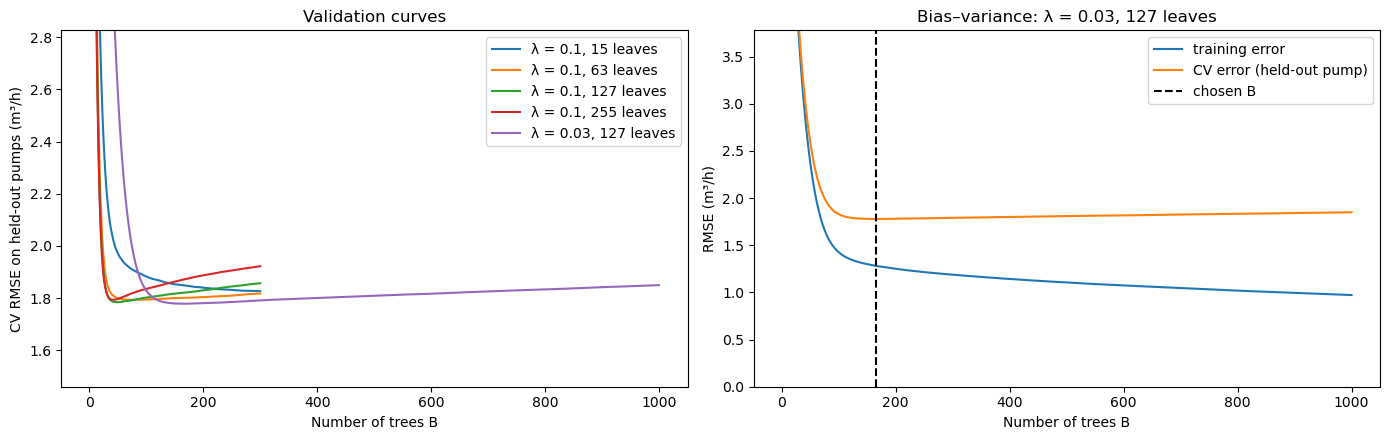

Best hyperparameters: {'learning_rate': 0.03, 'max_leaf_nodes': 127, 'max_iter': 165, 'min_samples_leaf': 20}


In [22]:
figure, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (learning_rate, max_leaf_nodes), (validation_curve, _) in tuning_curves.items():
    axes[0].plot(np.arange(1, len(validation_curve) + 1), validation_curve,
                 label=f"λ = {learning_rate}, {max_leaf_nodes} leaves")
axes[0].set_xlabel("Number of trees B")
axes[0].set_ylabel("CV RMSE on held-out pumps (m³/h)")
axes[0].set_ylim(top=tuning_table["CV_RMSE"].max() + 1)
axes[0].set_title("Validation curves")
axes[0].legend()

best_row = tuning_table.iloc[0]
best_key = (best_row["learning_rate"], int(best_row["max_leaf_nodes"]))
validation_curve, training_curve = tuning_curves[best_key]
trees = np.arange(1, len(validation_curve) + 1)
axes[1].plot(trees, training_curve, label="training error")
axes[1].plot(trees, validation_curve, label="CV error (held-out pump)")
axes[1].axvline(best_row["best_number_of_trees"], color="black", linestyle="--", label="chosen B")
axes[1].set_xlabel("Number of trees B")
axes[1].set_ylabel("RMSE (m³/h)")
axes[1].set_ylim(0, validation_curve.min() + 2)
axes[1].set_title(f"Bias–variance: λ = {best_key[0]}, {best_key[1]} leaves")
axes[1].legend()
plt.tight_layout()
plt.savefig(figures_folder + "task3_validation_curves.png", dpi=200, bbox_inches="tight")
plt.show()

best_hyperparameters = {"learning_rate": float(best_row["learning_rate"]),
                        "max_leaf_nodes": int(best_row["max_leaf_nodes"]),
                        "max_iter": int(best_row["best_number_of_trees"]),
                        "min_samples_leaf": 20}
print("Best hyperparameters:", best_hyperparameters)

**Reading the curves (bias–variance, Slides_3 p. 21, Slides_21 p. 21–22)**
- With few trees, both training and CV error are high: the model is too simple (**high bias**).
- As trees are added, the training error keeps falling, but the CV error flattens out and may start to rise:
  the extra trees fit details of the training pumps that do not transfer (**variance**). B is chosen where
  the CV curve is lowest.
- The gap between the training and CV curves is large. Part of it is overfitting, and part of it is
  unavoidable: the held-out pump is genuinely different from the training pumps, and with only 5 training
  pumps the model has seen little pump-to-pump variation.

**Selection vs assessment (Slides_3 p. 22–24).** All choices in sections 7–11 were made with the same CV folds.
The CV RMSE of the chosen settings is therefore slightly optimistic: it was used to *select* the model, not to
*assess* it. The honest estimate of performance on new pumps is the test error below, because the test set was
not used for any decision.

## 12. Final model: train on all of `train2.csv`, evaluate once on `test2.csv`

The final model is trained on **all** training rows (not only every 5th second), with the settings chosen above.

In [23]:
make_final_model = make_boosting(pca_components=final_pca_components, **best_hyperparameters)


def fit_and_predict(make_model, features, training_rows, prediction_sets, split_by_state):
    # Trains the model(s) once and returns predictions for each data set in prediction_sets
    all_predictions = [np.zeros(len(rows)) for rows in prediction_sets]
    for state in (["stable", "transient"] if split_by_state else ["all"]):
        train_mask = np.ones(len(training_rows), dtype=bool) if state == "all" else \
            (training_rows["operating_state"] == state).to_numpy()
        model = make_model()
        model.fit(training_rows.loc[train_mask, features], training_rows.loc[train_mask, target_name])
        for rows, predictions in zip(prediction_sets, all_predictions):
            mask = np.ones(len(rows), dtype=bool) if state == "all" else \
                (rows["operating_state"] == state).to_numpy()
            predictions[mask] = model.predict(rows.loc[mask, features])
    return all_predictions


predicted_flow, training_predictions = fit_and_predict(make_final_model, final_features, train_data,
                                                       [test_data, train_data], use_separate_models)

# Baselines for comparison
baseline_model = make_linear_baseline()
baseline_model.fit(train_data[case1_features], y_train)
baseline_predicted_flow = baseline_model.predict(test_data[case1_features])
mean_prediction = np.full(len(test_data), y_train.mean())

test_results = pd.DataFrame({
    "Predict the training mean": compute_errors(y_test, mean_prediction),
    "Linear regression baseline": compute_errors(y_test, baseline_predicted_flow),
    "M4 gradient boosting": compute_errors(y_test, predicted_flow),
}).T
print("Final features:", final_features)
print("PCA components:", final_pca_components)
print("Two separate models:", use_separate_models)
print("Hyperparameters:", best_hyperparameters)
print(f"M4 training RMSE (all training rows): {rmse(y_train, training_predictions):.3f}")
test_results.round(3)

Final features: ['speed_krpm', 'power_kw', 'pressure_difference_bar']
PCA components: None
Two separate models: False
Hyperparameters: {'learning_rate': 0.03, 'max_leaf_nodes': 127, 'max_iter': 165, 'min_samples_leaf': 20}
M4 training RMSE (all training rows): 1.453


,RMSE,MAE,R2,relative_error_pct
Predict the training mean,8.302,6.767,-0.001,102.575
Linear regression baseline,2.061,1.633,0.938,18.943
M4 gradient boosting,1.704,1.351,0.958,15.272


In [24]:
# Errors per operating state and per test pump
test_data["predicted_flow"] = predicted_flow
test_data["error"] = test_data[target_name] - test_data["predicted_flow"]

per_state = test_data.groupby("operating_state").apply(
    lambda rows: pd.Series(compute_errors(rows[target_name], rows["predicted_flow"])), include_groups=False)
per_pump = test_data.groupby("pump_id").apply(
    lambda rows: pd.Series(compute_errors(rows[target_name], rows["predicted_flow"])), include_groups=False)
print("Test errors per operating state")
print(per_state.round(3))
print("\nTest errors per pump")
print(per_pump.round(3))

Test errors per operating state
                  RMSE    MAE     R2  relative_error_pct
operating_state                                         
stable           1.675  1.324  0.965              15.433
transient        1.733  1.379  0.949              15.116

Test errors per pump
                    RMSE    MAE     R2  relative_error_pct
pump_id                                                   
99223362_model_06  1.538  1.258  0.965              16.517
99223362_model_07  1.505  1.177  0.970              12.150
99223362_model_08  1.786  1.449  0.948              16.555
99223362_model_09  1.568  1.217  0.969              11.934
99223362_model_10  1.783  1.362  0.961              11.610
99223362_model_11  2.255  1.964  0.912              25.781
99223362_model_12  1.345  1.017  0.975              11.106
99223362_model_13  1.498  1.216  0.965              15.124
99223362_model_14  1.615  1.240  0.958              12.709
99223362_model_15  1.957  1.614  0.937              19.315


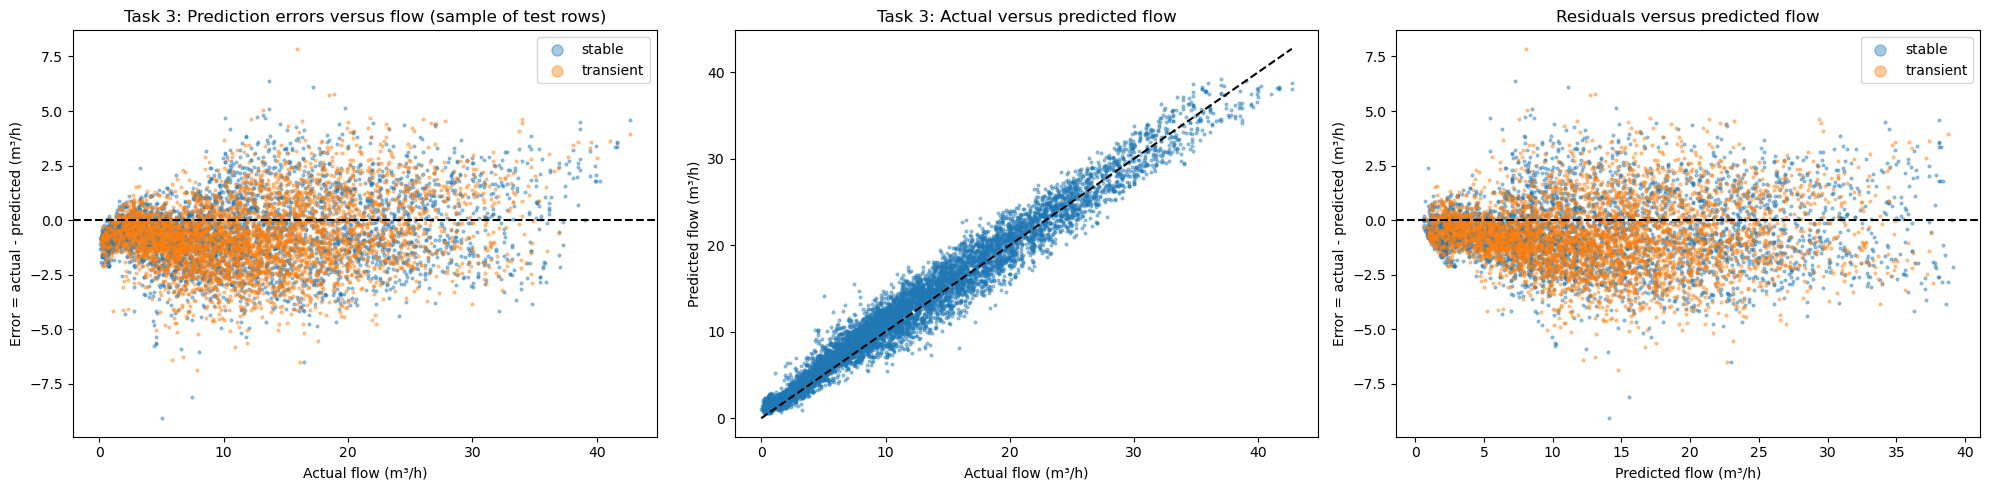

In [25]:
# Flow versus error plot (required), coloured by operating state, plus residuals versus predicted flow
plot_rows = test_data.sample(8000, random_state=0)
figure, axes = plt.subplots(1, 3, figsize=(20, 5))

for state, color in [("stable", "tab:blue"), ("transient", "tab:orange")]:
    rows = plot_rows[plot_rows["operating_state"] == state]
    axes[0].scatter(rows[target_name], rows["error"], s=4, alpha=0.4, color=color, label=state)
    axes[2].scatter(rows["predicted_flow"], rows["error"], s=4, alpha=0.4, color=color, label=state)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_xlabel("Actual flow (m³/h)")
axes[0].set_ylabel("Error = actual - predicted (m³/h)")
axes[0].set_title("Task 3: Prediction errors versus flow (sample of test rows)")
axes[0].legend(markerscale=4)

axes[1].scatter(plot_rows[target_name], plot_rows["predicted_flow"], s=4, alpha=0.4)
limits = [0, max(plot_rows[target_name].max(), plot_rows["predicted_flow"].max())]
axes[1].plot(limits, limits, "k--")
axes[1].set_xlabel("Actual flow (m³/h)")
axes[1].set_ylabel("Predicted flow (m³/h)")
axes[1].set_title("Task 3: Actual versus predicted flow")

axes[2].axhline(0, color="black", linestyle="--")
axes[2].set_xlabel("Predicted flow (m³/h)")
axes[2].set_ylabel("Error = actual - predicted (m³/h)")
axes[2].set_title("Residuals versus predicted flow")
axes[2].legend(markerscale=4)
plt.tight_layout()
plt.savefig(figures_folder + "task3_error_vs_flow.png", dpi=200, bbox_inches="tight")
plt.show()

> *Added after review:* the third panel plots the residuals against the **predicted** flow, which is the standard
> residual diagnostic (Slides_2 p. 30–33). Plotting against the *actual* flow (required by the brief) always shows
> a tilt for any model that shrinks towards the mean, so the predicted-flow version is the fairer check for
> systematic bias: a curved or shifted cloud means the model is biased in that range.

In [26]:
# Is the error larger for some flow ranges? Mean error (bias) and MAE per bin of actual and of predicted flow.
flow_bins = [0, 2, 5, 10, 15, 20, 30, 45]
for column in [target_name, "predicted_flow"]:
    bins = pd.cut(test_data[column], bins=flow_bins)
    print(f"Binned by {column}:")
    print(test_data.groupby(bins, observed=True)["error"].agg(
        rows="size", mean_error="mean", MAE=lambda errors: errors.abs().mean()).round(3), "\n")

Binned by flow_m3_h:
            rows  mean_error    MAE
flow_m3_h                          
(0, 2]      8535      -0.749  0.791
(2, 5]     15935      -0.764  0.914
(5, 10]    30270      -1.042  1.314
(10, 15]   25262      -0.775  1.564
(15, 20]   17614      -0.439  1.535
(20, 30]   17880      -0.074  1.464
(30, 45]    4404       0.595  1.859 

Binned by predicted_flow:
                 rows  mean_error    MAE
predicted_flow                          
(0, 2]           5742      -0.516  0.642
(2, 5]          14273      -0.492  0.690
(5, 10]         29536      -0.675  1.214
(10, 15]        27226      -0.807  1.559
(15, 20]        19199      -0.757  1.629
(20, 30]        19582      -0.454  1.582
(30, 45]         4342      -0.187  1.830 



In [27]:
# Worst test pump: are its inputs unusual compared with the training pumps?
worst_pump = per_pump["RMSE"].idxmax()
check_columns = ["speed_krpm", "power_kw", "pressure_difference_bar", "current_a", target_name]
input_summary = pd.concat({
    "training pumps (all)": train_data[check_columns].mean(),
    "test pumps (all)": test_data[check_columns].mean(),
    f"worst test pump ({worst_pump})": test_data.loc[test_data["pump_id"] == worst_pump, check_columns].mean(),
}, axis=1)
print("Mean of each input:")
print(input_summary.round(3))

worst_rows = test_data[test_data["pump_id"] == worst_pump]
outside_range = {column: 100 * ((worst_rows[column] < train_data[column].min()) |
                                (worst_rows[column] > train_data[column].max())).mean()
                 for column in check_columns[:-1]}
print("\n% of the worst pump's rows outside the training range:", {k: round(v, 2) for k, v in outside_range.items()})
print("Mean error of the worst pump (positive = underpredicts):", round(worst_rows["error"].mean(), 3))

Mean of each input:
                         training pumps (all)  test pumps (all)  \
speed_krpm                              2.502             2.502   
power_kw                                0.307             0.316   
pressure_difference_bar                 0.436             0.435   
current_a                               0.504             0.518   
flow_m3_h                              12.667            12.430   

                         worst test pump (99223362_model_11)  
speed_krpm                                             2.501  
power_kw                                               0.325  
pressure_difference_bar                                0.452  
current_a                                              0.534  
flow_m3_h                                             11.398  

% of the worst pump's rows outside the training range: {'speed_krpm': np.float64(0.01), 'power_kw': np.float64(0.07), 'pressure_difference_bar': np.float64(0.01), 'current_a': np.float64(0.13)}
Mean

> *Added after review:* this checks the worst test pump. If its inputs lie inside the training range but the
> error is still large and mostly of one sign, the pump behaves differently from the training pumps (a
> pump-specific offset). That cannot be fixed with more tuning, only with more varied training pumps or
> pump-level information (see the outlook below).

In [28]:
print(f"Whole notebook ran in {(time.time() - notebook_start_time) / 60:.1f} minutes")

Whole notebook ran in 12.8 minutes


## 13. Notes for the report

- **Leakage:** all model choices (features, one vs two models, PCA, hyperparameters) were made with
  leave-one-pump-out CV on `train2.csv`. The test set was used once, at the end.
- **Selection vs assessment:** the CV RMSE was used to choose the model, so it is slightly optimistic.
  The test RMSE is the honest estimate. Compare the two: if the test RMSE is close to the CV RMSE, the grouped
  CV was a good stand-in for new pumps.
- **Uncertainty:** with only 5 training pumps the CV estimate is noisy (`RMSE_SE`), so decisions used the
  one-standard-error rule instead of picking the lowest number.
- **Bias–variance:** the validation curves (figure `task3_validation_curves.png`) show where adding trees
  stops helping, and the gap between training and CV error shows how much the model overfits the training pumps.
- **Per-pump and per-state test errors** show whether the model fails on specific pumps or during transients.
- **GenAI:** this notebook was developed with help from Claude (Anthropic). Cite this in the report, as the
  brief requires.

## 14. Extensions and alternative approaches

**Features**
- **Lag / change features for transients.** Rows are one second apart and the state alternates every
  10 seconds. During a transient the flow may lag behind speed and pressure changes. Add, per pump and
  sorted by `elapsed_s`: the change since the previous second (`diff`), the value a few seconds ago, or a
  short rolling mean. `elapsed_s` is then used only to order the rows, not as a feature. Compute these
  within each pump so values never cross from one pump to another.
- **Physics-based features (affinity laws).** For centrifugal pumps, Q scales with n, Δp with n², and
  P with n³. Features such as Δp/n², P/n³ and Q/n (predict Q/n and multiply back) can make different
  speeds look alike, which may help generalise to new pumps.
- **Use the Task 0 equation.** Task 0 gives P as a polynomial in n and Q. For a given n and P you can
  solve it for Q and use that estimate as an extra feature, or as a baseline model.

**Models**
- **Random forest or extra trees** as a second M4 candidate. Bagging reduces variance (Slides_15 p. 7), while
  boosting reduces bias but "can hurt performance if the data set is too noisy" (Slides_15 p. 28). The large gap
  between training and CV error suggests variance is the bigger problem, so a random forest is worth trying.
  Its out-of-bag error and feature importances (Slides_15 p. 10, 15) are useful extras.
- **Neural network** (your M2 from Task 2, or `MLPRegressor`) with scaled inputs. It gives a smooth
  function, which may extrapolate better than trees to pumps that operate slightly outside the
  training range (trees predict a constant outside the training range).
- **Sequence models** (1D CNN or LSTM over a sliding window of seconds) to model transients directly.
- **Ensemble / stacking:** average or stack the predictions of boosting and a neural network (Slides_15 p. 29).

**Training and tuning**
- **Nested CV** would give an unbiased CV estimate of the whole selection procedure (an inner loop for choosing
  settings, an outer loop for assessing them). With only 5 pumps it is expensive and noisy, so here the
  untouched test set plays the role of the outer loop.
- **Loss function:** if relative error matters most to the customer, train on log(flow) or use a loss
  that weighs low flows more.
- **Prediction intervals:** quantile gradient boosting (`loss="quantile"`) gives a range for each prediction,
  which is useful for a company monitoring pumps.

**Outlook (data collection, for the report)**
- More training pumps would make the model generalise better, since 5 pumps is a small sample of pump-to-pump variation.
- Record pump characteristics (impeller size, model, motor efficiency) so the model can explain why pumps differ.
- Calibrate each customer pump briefly with a flow meter at installation, then use that data to adjust the model.
- Temperature sensors that vary with operating conditions (rather than per-pump constants) would make temperature useful.